# RBERS — Version 2: Corrected Stop-Go Energy Model

This version fixes the first model's main issue: the drive cycle itself now produces **exactly 50 braking events/hour**, matching the midpoint of the SOLVE proposal's stated 40–60 events/hour. It also calculates traction and braking energy from the speed profile instead of treating the vehicle as a sequence of disconnected energy calculations.

**Important:** vehicle mass, battery size, rolling resistance, aerodynamic parameters and component efficiencies below are assumptions because the proposal does not specify them. The 20–25% RBERS figures remain targets to test, not measured results.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =============================
# 1. INPUTS
# =============================

# Proposal-based operating conditions
mass_kg = 700                 # ASSUMPTION: vehicle + driver + payload
cruise_speed_kmh = 25        # proposal: 20–25 km/h
braking_events_per_hour = 50 # proposal: 40–60 events/hour

# The cycle is constructed to give EXACTLY 50 events/hour:
# 3600 / 50 = 72 seconds per stop-go cycle
cycle_time_s = 3600 / braking_events_per_hour
accel_time_s = 10
cruise_time_s = 52
brake_time_s = 10

assert accel_time_s + cruise_time_s + brake_time_s == cycle_time_s

# Vehicle assumptions — not specified in the proposal
Cd = 0.8                       # assumed drag coefficient
frontal_area_m2 = 2.0         # assumed frontal area
air_density = 1.225           # kg/m^3
rolling_resistance = 0.015
g = 9.81

# Electrical-system assumptions for the first engineering model
drivetrain_efficiency = 0.90
motor_generator_efficiency = 0.90
rectifier_efficiency = 0.97
converter_efficiency = 0.95
battery_charge_efficiency = 0.95
battery_capacity_kwh = 6.0    # assumed only for range comparison

print(f'Cycle time: {cycle_time_s:.0f} s')
print(f'Braking events/hour: {3600/cycle_time_s:.0f}')
print(f'Cruise speed: {cruise_speed_kmh} km/h')


Cycle time: 72 s
Braking events/hour: 50
Cruise speed: 25 km/h


## 2. Generate the corrected 1-hour drive cycle

The vehicle accelerates to 25 km/h, cruises, then brakes to zero. There are exactly 50 complete stop events in one hour.


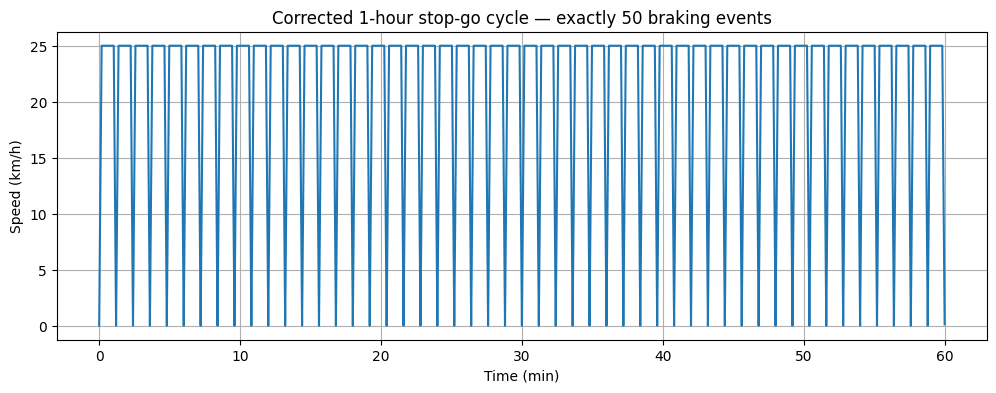

In [2]:
dt = 0.05
t = np.arange(0, 3600, dt)
speed_kmh = np.zeros_like(t)

for i, ti in enumerate(t):
    phase = ti % cycle_time_s

    if phase < accel_time_s:
        speed_kmh[i] = cruise_speed_kmh * phase / accel_time_s
    elif phase < accel_time_s + cruise_time_s:
        speed_kmh[i] = cruise_speed_kmh
    else:
        brake_phase = phase - accel_time_s - cruise_time_s
        speed_kmh[i] = cruise_speed_kmh * (1 - brake_phase / brake_time_s)

speed_ms = speed_kmh / 3.6

plt.figure(figsize=(12,4))
plt.plot(t/60, speed_kmh)
plt.xlabel('Time (min)')
plt.ylabel('Speed (km/h)')
plt.title('Corrected 1-hour stop-go cycle — exactly 50 braking events')
plt.grid(True)
plt.show()


In [3]:
# Basic cycle checks
distance_km = np.trapezoid(speed_ms, t) / 1000
avg_speed_kmh = distance_km

print(f'Distance in 1 hour: {distance_km:.2f} km')
print(f'Average speed: {avg_speed_kmh:.2f} km/h')
print(f'Expected braking events: {3600/cycle_time_s:.0f}/hour')


Distance in 1 hour: 21.53 km
Average speed: 21.53 km/h
Expected braking events: 50/hour


## 3. Calculate acceleration, rolling resistance and aerodynamic drag

We now calculate the mechanical force required to follow the speed profile. This is more physically meaningful than simply multiplying a fixed energy value by the number of stops.


In [4]:
accel_ms2 = np.gradient(speed_ms, dt)

F_inertia = mass_kg * accel_ms2
F_roll = np.full_like(t, rolling_resistance * mass_kg * g)
F_aero = 0.5 * air_density * Cd * frontal_area_m2 * speed_ms**2

# Positive force = traction demand; negative force = braking demand
F_total = F_inertia + F_roll + F_aero
P_mech_w = F_total * speed_ms

# Traction power only
P_traction_w = np.maximum(P_mech_w, 0)

# Mechanical braking power available when the vehicle is decelerating.
# We exclude normal rolling/air resistance here because those losses are not recoverable.
P_brake_available_w = np.maximum(-mass_kg * accel_ms2 * speed_ms, 0)

traction_energy_wh = np.trapezoid(P_traction_w, t) / 3600
braking_energy_available_wh = np.trapezoid(P_brake_available_w, t) / 3600

print(f'Traction mechanical energy: {traction_energy_wh:.1f} Wh/hour')
print(f'Mechanical braking energy available: {braking_energy_available_wh:.1f} Wh/hour')
print(f'Braking energy per stop: {braking_energy_available_wh/(3600/cycle_time_s):.2f} Wh')


Traction mechanical energy: 1048.8 Wh/hour
Mechanical braking energy available: 234.4 Wh/hour
Braking energy per stop: 4.69 Wh


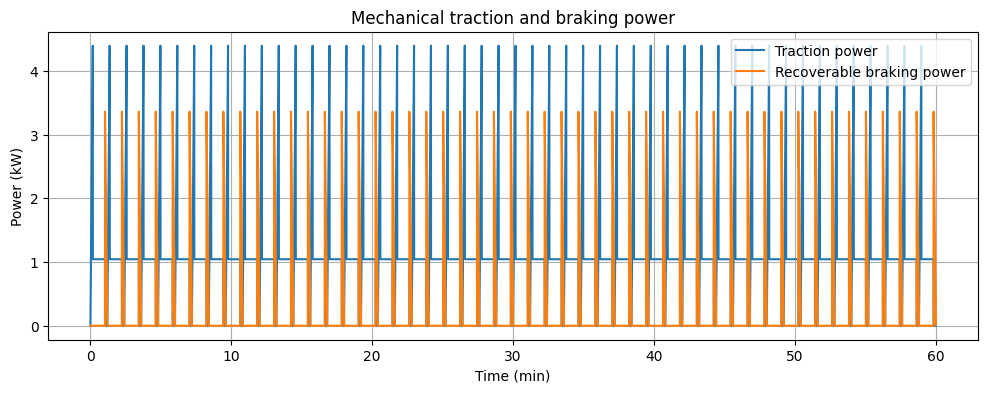

In [5]:
plt.figure(figsize=(12,4))
plt.plot(t/60, P_traction_w/1000, label='Traction power')
plt.plot(t/60, P_brake_available_w/1000, label='Recoverable braking power')
plt.xlabel('Time (min)')
plt.ylabel('Power (kW)')
plt.title('Mechanical traction and braking power')
plt.legend()
plt.grid(True)
plt.show()


## 4. Model the RBERS energy path

Here we separate the proposal's **20% and 25% recovery targets** from the downstream electrical losses. This lets us see how much energy could reach the battery after motor/generator, rectifier, converter and battery-charge losses.

This is still a reduced-order model. We are **not yet claiming to have simulated the ADBMS6815, LTC3325, LM10011, MOSFET switching or ultracapacitor electrochemistry in detail**.


In [6]:
recovery_targets = [0.00, 0.05, 0.08, 0.20, 0.25]
case_names = ['No regen', 'Budget 5%', 'Budget 8%', 'RBERS 20%', 'RBERS 25%']

path_efficiency = (
    motor_generator_efficiency
    * rectifier_efficiency
    * converter_efficiency
    * battery_charge_efficiency
)

rows = []
for name, target in zip(case_names, recovery_targets):
    recovered_before_losses_wh = braking_energy_available_wh * target
    stored_wh = recovered_before_losses_wh * path_efficiency
    rows.append([
        name, target*100, recovered_before_losses_wh, path_efficiency*100, stored_wh
    ])

recovery_table = pd.DataFrame(rows, columns=[
    'Case', 'Target recovery (%)', 'Recovered before electrical losses (Wh/h)',
    'Downstream path efficiency (%)', 'Energy stored in battery equivalent (Wh/h)'
])

recovery_table.round(2)


,Case,Target recovery (%),Recovered before electrical losses (Wh/h),Downstream path efficiency (%),Energy stored in battery equivalent (Wh/h)
0,No regen,0.0,0.00,78.79,0.00
1,Budget 5%,5.0,11.72,78.79,9.24
2,Budget 8%,8.0,18.75,78.79,14.78
3,RBERS 20%,20.0,46.89,78.79,36.94
4,RBERS 25%,25.0,58.61,78.79,46.18


## 5. Compare energy consumption and range

The battery-side traction demand is estimated from mechanical traction energy divided by drivetrain efficiency. Recovered energy is then subtracted from that demand.


In [7]:
battery_traction_demand_wh = traction_energy_wh / drivetrain_efficiency
baseline_wh_per_km = battery_traction_demand_wh / distance_km
baseline_range_km = battery_capacity_kwh * 1000 / baseline_wh_per_km

range_rows = []
for name, target in zip(case_names, recovery_targets):
    stored_wh = braking_energy_available_wh * target * path_efficiency
    net_battery_energy_wh = battery_traction_demand_wh - stored_wh
    wh_per_km = net_battery_energy_wh / distance_km
    estimated_range_km = battery_capacity_kwh * 1000 / wh_per_km
    improvement = (estimated_range_km / baseline_range_km - 1) * 100

    range_rows.append([
        name, battery_traction_demand_wh, stored_wh, net_battery_energy_wh,
        wh_per_km, estimated_range_km, improvement
    ])

range_table = pd.DataFrame(range_rows, columns=[
    'Case', 'Battery traction demand (Wh/h)', 'Recovered/stored energy (Wh/h)',
    'Net battery energy (Wh/h)', 'Consumption (Wh/km)',
    'Estimated range (km)', 'Range improvement (%)'
])

range_table.round(2)


,Case,Battery traction demand (Wh/h),Recovered/stored energy (Wh/h),Net battery energy (Wh/h),Consumption (Wh/km),Estimated range (km),Range improvement (%)
0,No regen,1165.32,0.00,1165.32,54.13,110.84,0.00
1,Budget 5%,1165.32,9.24,1156.08,53.70,111.73,0.80
2,Budget 8%,1165.32,14.78,1150.54,53.44,112.27,1.28
3,RBERS 20%,1165.32,36.94,1128.38,52.41,114.47,3.27
4,RBERS 25%,1165.32,46.18,1119.14,51.99,115.42,4.13


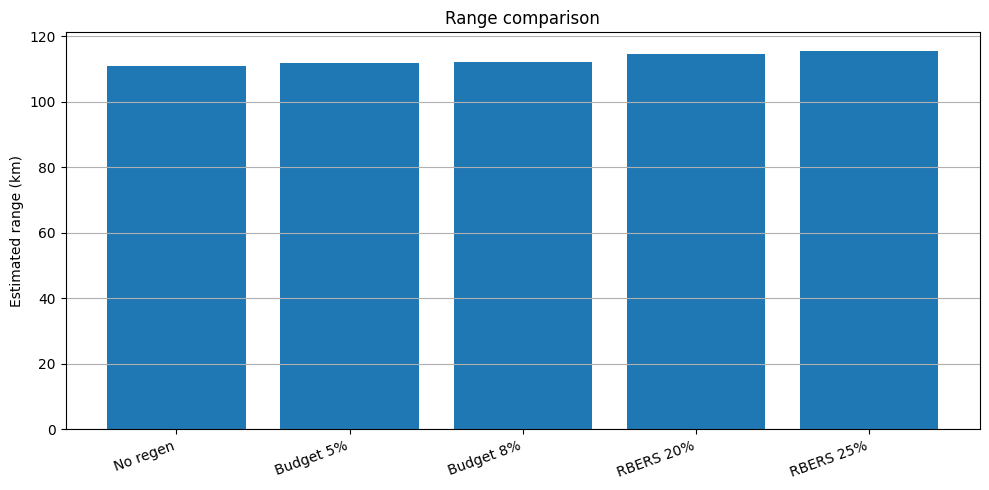

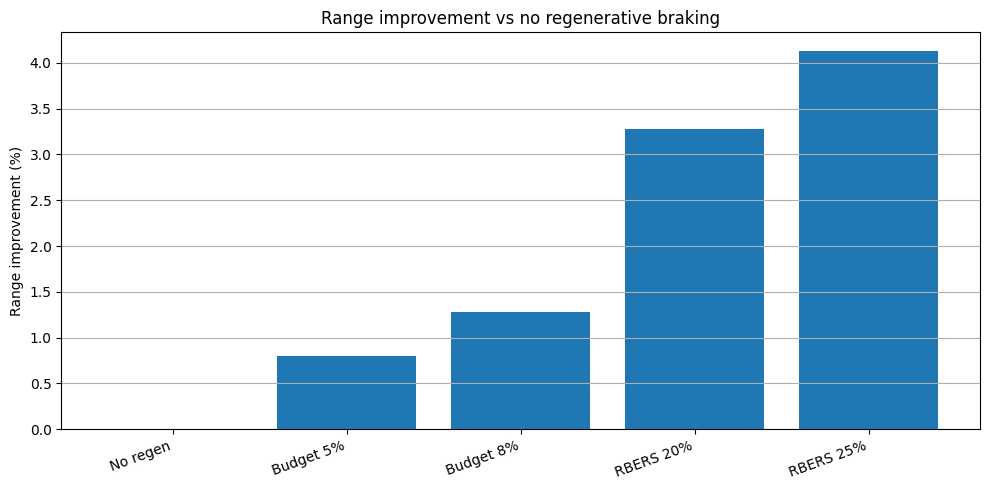

In [8]:
plt.figure(figsize=(10,5))
plt.bar(range_table['Case'], range_table['Estimated range (km)'])
plt.ylabel('Estimated range (km)')
plt.title('Range comparison')
plt.xticks(rotation=20, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,5))
plt.bar(range_table['Case'], range_table['Range improvement (%)'])
plt.ylabel('Range improvement (%)')
plt.title('Range improvement vs no regenerative braking')
plt.xticks(rotation=20, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()


## 6. Key engineering outputs

Run this cell after the tables above. These are the numbers we will carry into the next model.


In [9]:
rb20 = range_table.loc[range_table['Case']=='RBERS 20%'].iloc[0]
rb25 = range_table.loc[range_table['Case']=='RBERS 25%'].iloc[0]

print('===== KEY OUTPUTS =====')
print(f'Distance per hour: {distance_km:.2f} km')
print(f'Braking events per hour: {3600/cycle_time_s:.0f}')
print(f'Braking energy available: {braking_energy_available_wh:.2f} Wh/h')
print(f'Braking energy per stop: {braking_energy_available_wh/(3600/cycle_time_s):.2f} Wh')
print(f'RBERS 20%: {rb20["Recovered/stored energy (Wh/h)"]:.2f} Wh/h stored')
print(f'RBERS 25%: {rb25["Recovered/stored energy (Wh/h)"]:.2f} Wh/h stored')
print(f'RBERS 20% range improvement: {rb20["Range improvement (%)"]:.2f}%')
print(f'RBERS 25% range improvement: {rb25["Range improvement (%)"]:.2f}%')


===== KEY OUTPUTS =====
Distance per hour: 21.53 km
Braking events per hour: 50
Braking energy available: 234.43 Wh/h
Braking energy per stop: 4.69 Wh
RBERS 20%: 36.94 Wh/h stored
RBERS 25%: 46.18 Wh/h stored
RBERS 20% range improvement: 3.27%
RBERS 25% range improvement: 4.13%
